### **Install libraries**

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost shap lime joblib scipy

### **Import libraries**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer
import joblib
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


### **Load dataset**

In [3]:
import os

DATASET_PATH = "/content/healthcare-dataset-stroke-data.csv"

if os.path.exists(DATASET_PATH):
    df = pd.read_csv(DATASET_PATH)
    print(f"Dataset loaded: {DATASET_PATH}")
else:

    from google.colab import files
    print(f"⚠️ {DATASET_PATH} not found. Please upload the CSV.")
    uploaded = files.upload()

    filename = list(uploaded.keys())[0]
    df = pd.read_csv(filename)
    df.to_csv(DATASET_PATH, index=False)
    print(f" Saved as: {DATASET_PATH}")

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Dataset loaded: /content/healthcare-dataset-stroke-data.csv
Rows: 5110, Columns: 12


### **Inspect dataset**

In [4]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
print("Rows:", df.shape[0])

print("Columns:", df.shape[1])

print(df.columns.tolist())

Rows: 5110
Columns: 12
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [7]:
df.describe(include="all")

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


In [8]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStroke distribution:")
print(df["stroke"].value_counts(dropna=False))

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Duplicate rows: 0

Stroke distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


### **Data cleaning**

In [9]:
df.columns = df.columns.str.strip()

text_columns = [
    "gender", "ever_married", "work_type",
    "Residence_type", "smoking_status"
]

for column in text_columns:
    df[column] = df[column].astype("string").str.strip()

print("Column names and text values cleaned.")

Column names and text values cleaned.


In [10]:
df = df.replace(["N/A", "NA", "na", "null", "NULL", "None", ""], np.nan)

numeric_columns = [
    "age", "hypertension", "heart_disease",
    "avg_glucose_level", "bmi", "stroke"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print(df.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [11]:
print("Duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows after:", df.duplicated().sum())

print("Duplicate IDs:", df["id"].duplicated().sum())

Duplicate rows before: 0
Duplicate rows after: 0
Duplicate IDs: 0


In [12]:
print("Invalid ages below 0:")
print(df[df["age"] < 0])

print("\nInvalid ages above 120:")
print(df[df["age"] > 120])

print("\nBMI summary:")
print(df["bmi"].describe())

print("\nGlucose summary:")
print(df["avg_glucose_level"].describe())

Invalid ages below 0:
Empty DataFrame
Columns: [id, gender, age, hypertension, heart_disease, ever_married, work_type, Residence_type, avg_glucose_level, bmi, smoking_status, stroke]
Index: []

Invalid ages above 120:
Empty DataFrame
Columns: [id, gender, age, hypertension, heart_disease, ever_married, work_type, Residence_type, avg_glucose_level, bmi, smoking_status, stroke]
Index: []

BMI summary:
count    4909.000000
mean       28.893237
std         7.854067
min        10.300000
25%        23.500000
50%        28.100000
75%        33.100000
max        97.600000
Name: bmi, dtype: float64

Glucose summary:
count    5110.000000
mean      106.147677
std        45.283560
min        55.120000
25%        77.245000
50%        91.885000
75%       114.090000
max       271.740000
Name: avg_glucose_level, dtype: float64


In [13]:
for column in text_columns:
    print("\n" + column)
    print(df[column].value_counts(dropna=False))


gender
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: Int64

ever_married
ever_married
Yes    3353
No     1757
Name: count, dtype: Int64

work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: Int64

Residence_type
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: Int64

smoking_status
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: Int64


In [14]:
df = df.dropna(subset=["stroke"]).reset_index(drop=True)
df["stroke"] = df["stroke"].astype(int)

print("Final cleaned shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Final cleaned shape: (5110, 12)

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


### **Exploratory Data Analysis**

Stroke Distribution

In [15]:
import plotly.express as px

fig = px.histogram(
    df,
    x="stroke",
    color="stroke",
    text_auto=True,
    title="Stroke Distribution",
    labels={
        "stroke": "Stroke",
        "count": "Number of Patients"
    },
    color_discrete_map={
        0: "#4C78A8",
        1: "#E45756"
    }
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="Stroke Distribution",
        x=0.5,
        font=dict(size=22)
    ),
    xaxis=dict(
        tickmode="array",
        tickvals=[0, 1],
        ticktext=["No Stroke", "Stroke"],
        title="Stroke"
    ),
    yaxis_title="Number of Patients",
    showlegend=False,
    bargap=0.25,
    height=450
)

fig.show()

Age Distribution

In [16]:
import plotly.express as px
import numpy as np
from scipy.stats import gaussian_kde

x = df["age"].dropna().values

fig = px.histogram(
    df,
    x="age",
    nbins=30,
    title="Age Distribution",
    labels={
        "age": "Age",
        "count": "Number of People"
    },
    opacity=0.85
)

kde = gaussian_kde(x)
x_kde = np.linspace(x.min(), x.max(), 200)
y_kde = kde(x_kde)

bin_width = (x.max() - x.min()) / 30
y_kde = y_kde * len(x) * bin_width

fig.add_scatter(
    x=x_kde,
    y=y_kde,
    mode="lines",
    name="KDE",
    line=dict(
        color="#7B2CBF",
        width=3
    )
)

fig.update_traces(
    selector=dict(type="histogram"),
    marker=dict(
        color="#00B4D8",
        line=dict(
            color="#FFFFFF",
            width=1
        )
    )
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="Age Distribution",
        x=0.5,
        font=dict(
            size=22,
            color="#2D3047"
        )
    ),
    xaxis=dict(
        title="Age",
        showgrid=True,
        gridcolor="#E5E7EB"
    ),
    yaxis=dict(
        title="Number of People",
        showgrid=True,
        gridcolor="#E5E7EB"
    ),
    bargap=0.05,
    height=450,
    legend=dict(
        title="Distribution"
    )
)

fig.show()

BMI Distribution

In [17]:
import plotly.express as px

fig = px.histogram(
    df,
    x="bmi",
    nbins=30,
    title="BMI Distribution",
    labels={"bmi": "BMI", "count": "Number of People"},
    marginal="box",
    opacity=0.9
)

fig.update_traces(
    marker=dict(
        color="#636EFA",
        line=dict(color="white", width=1)
    )
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="BMI Distribution",
        x=0.5,
        font=dict(size=22)
    ),
    xaxis=dict(
        title="BMI",
        showgrid=True,
        gridcolor="lightgray"
    ),
    yaxis=dict(
        title="Number of People",
        showgrid=True,
        gridcolor="lightgray"
    ),
    bargap=0.05,
    height=500
)

fig.show()

Pair Plot of Key Stroke Prediction Features

In [18]:
pair_df = df[
    ["age", "bmi", "avg_glucose_level", "stroke"]
].dropna()

pair_df["stroke"] = pair_df["stroke"].map({
    0: "No Stroke",
    1: "Stroke"
})

fig = px.scatter_matrix(
    pair_df,
    dimensions=[
        "age",
        "bmi",
        "avg_glucose_level"
    ],
    color="stroke",
    color_discrete_map={
        "No Stroke": "#00B4D8",
        "Stroke": "#7B2CBF"
    },
    title="Pair Plot of Key Stroke Prediction Features",
    opacity=0.65
)

fig.update_traces(
    diagonal_visible=False,
    showupperhalf=True,
    marker=dict(size=5)
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="Pair Plot of Key Stroke Prediction Features",
        x=0.5,
        font=dict(size=20)
    ),
    height=750,
    width=900
)

fig.show()

### **Statistical feature analysis**

In [19]:
correlation_columns = [
    "age", "hypertension", "heart_disease",
    "avg_glucose_level", "bmi", "stroke"
]

correlation = df[correlation_columns].corr()
display(correlation)

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
age,1.000000,0.276398,0.263796,0.238171,0.333398,0.245257
hypertension,0.276398,1.000000,0.108306,0.174474,0.167811,0.127904
heart_disease,0.263796,0.108306,1.000000,0.161857,0.041357,0.134914
avg_glucose_level,0.238171,0.174474,0.161857,1.000000,0.175502,0.131945
bmi,0.333398,0.167811,0.041357,0.175502,1.000000,0.042374
stroke,0.245257,0.127904,0.134914,0.131945,0.042374,1.000000


Correlation Matrix

In [20]:
correlation = df.corr(numeric_only=True)

fig = px.imshow(
    correlation,
    text_auto=".2f",
    color_continuous_scale=[
        [0.0, "#7B2CBF"],
        [0.5, "#F8F9FA"],
        [1.0, "#00B4D8"]
    ],
    title="Correlation Matrix",
    aspect="auto"
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="Correlation Matrix",
        x=0.5,
        font=dict(
            size=22,
            color="#2D3047"
        )
    ),
    height=600,
    width=750,
    coloraxis_colorbar=dict(
        title="Correlation"
    )
)

fig.update_traces(
    textfont=dict(
        size=12,
        color="#222222"
    )
)

fig.show()

### **Chi-Square Analysis**

In [21]:
categorical_columns = [
    "gender", "ever_married", "work_type",
    "Residence_type", "smoking_status"
]

for column in categorical_columns:
    table = pd.crosstab(df[column], df["stroke"])
    chi2, p, dof, expected = chi2_contingency(table)
    print("Feature:", column)
    print("Chi-square:", round(chi2,4))
    print("p-value:", round(p,6))
    print("Significant at p < 0.05:", p < 0.05)
    print("-"*40)

Feature: gender
Chi-square: 0.4726
p-value: 0.789549
Significant at p < 0.05: False
----------------------------------------
Feature: ever_married
Chi-square: 58.9239
p-value: 0.0
Significant at p < 0.05: True
----------------------------------------
Feature: work_type
Chi-square: 49.1635
p-value: 0.0
Significant at p < 0.05: True
----------------------------------------
Feature: Residence_type
Chi-square: 1.0816
p-value: 0.298332
Significant at p < 0.05: False
----------------------------------------
Feature: smoking_status
Chi-square: 29.1473
p-value: 2e-06
Significant at p < 0.05: True
----------------------------------------


### **Feature Engineering**

In [22]:
def create_engineered_features(df):
    """
    Feature engineering used in training AND inference.
    Guarantees training and Gradio use identical logic.
    """
    df = df.copy()

    df['age_group'] = pd.cut(
        df['age'],
        bins=[0, 40, 60, 80, 120],
        labels=['<40', '40-60', '60-80', '>80']
    )

    df['bmi_category'] = pd.cut(
        df['bmi'],
        bins=[0, 18.5, 25, 30, 100],
        labels=['Underweight', 'Normal', 'Overweight', 'Obese']
    )

    df['glucose_category'] = pd.cut(
        df['avg_glucose_level'],
        bins=[0, 100, 126, 200, 500],
        labels=['Normal', 'Prediabetes', 'Diabetes', 'High']
    )

    df['age_bmi_interaction'] = df['age'] * df['bmi']
    df['age_glucose_interaction'] = df['age'] * df['avg_glucose_level']
    df['cardiac_risk'] = df['hypertension'] + df['heart_disease']

    return df

df = create_engineered_features(df)

print(" Feature engineering completed!")
print(f"Total features: {df.shape[1]}")
print("\nCategory levels (used in BOTH training and Gradio):")
print(f"  age_group:        {df['age_group'].cat.categories.tolist()}")
print(f"  bmi_category:     {df['bmi_category'].cat.categories.tolist()}")
print(f"  glucose_category: {df['glucose_category'].cat.categories.tolist()}")

 Feature engineering completed!
Total features: 18

Category levels (used in BOTH training and Gradio):
  age_group:        ['<40', '40-60', '60-80', '>80']
  bmi_category:     ['Underweight', 'Normal', 'Overweight', 'Obese']
  glucose_category: ['Normal', 'Prediabetes', 'Diabetes', 'High']


### **Train/test split**

In [23]:
X = df.drop("stroke", axis=1)
y = df["stroke"]

X = X.drop("id", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("\nTraining target:")
print(y_train.value_counts())
print("\nTesting target:")
print(y_test.value_counts())

Training: (4088, 16)
Testing: (1022, 16)

Training target:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing target:
stroke
0    972
1     50
Name: count, dtype: int64


### **Preprocessing pipeline**

In [24]:

numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi",
    "age_bmi_interaction",
    "age_glucose_interaction",
    "cardiac_risk"
]

categorical_features = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
    "age_group",
    "bmi_category",
    "glucose_category"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing setup completed.")

Preprocessing setup completed.


### **Model Training and Stratified 5-Fold Cross-Validation with SMOTE**

In [25]:

from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

base_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss"
    )
}


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


cv_results = []

for name, model in base_models.items():

    cv_pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    scores = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        n_jobs=-1
    )

    cv_results.append([
        name,
        scores["test_accuracy"].mean(),
        scores["test_precision"].mean(),
        scores["test_recall"].mean(),
        scores["test_f1"].mean(),
        scores["test_roc_auc"].mean()
    ])

cv_results_df = pd.DataFrame(
    cv_results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
)

print("Corrected 5-fold cross-validation results:")

display(cv_results_df.round(4))

Corrected 5-fold cross-validation results:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7463,0.1384,0.8040,0.2361,0.8481
1,Decision Tree,0.7776,0.1287,0.6181,0.2122,0.7953
2,Random Forest,0.8765,0.1542,0.3572,0.2147,0.8200
3,XGBoost,0.9462,0.3404,0.0858,0.1322,0.8225


Final Model Training Using Preprocessing and SMOTE Pipelines

In [26]:
final_pipelines = {}

for name, model in base_models.items():

    pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    final_pipelines[name] = pipeline

print("All final models trained successfully.")

All final models trained successfully.


Generating Test Predictions and Class Probabilities for All Models

In [27]:
logistic_prediction = final_pipelines[
    "Logistic Regression"
].predict(X_test)

logistic_probability = final_pipelines[
    "Logistic Regression"
].predict_proba(X_test)[:, 1]


decision_tree_prediction = final_pipelines[
    "Decision Tree"
].predict(X_test)

decision_tree_probability = final_pipelines[
    "Decision Tree"
].predict_proba(X_test)[:, 1]


random_forest_prediction = final_pipelines[
    "Random Forest"
].predict(X_test)

random_forest_probability = final_pipelines[
    "Random Forest"
].predict_proba(X_test)[:, 1]


xgb_prediction = final_pipelines[
    "XGBoost"
].predict(X_test)

xgb_probability = final_pipelines[
    "XGBoost"
].predict_proba(X_test)[:, 1]

print("Test predictions generated successfully.")

Test predictions generated successfully.


### **Final test evaluation**

In [28]:
results = []

for name, pipeline in final_pipelines.items():

    prediction = pipeline.predict(X_test)
    probability = pipeline.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_test, prediction),
        precision_score(
            y_test, prediction, zero_division=0
        ),
        recall_score(
            y_test, prediction, zero_division=0
        ),
        f1_score(
            y_test, prediction, zero_division=0
        ),
        roc_auc_score(y_test, probability)
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7642,0.1423,0.76,0.2397,0.8390
1,Decision Tree,0.7701,0.1373,0.70,0.2295,0.7829
2,Random Forest,0.8728,0.1875,0.48,0.2697,0.8180
3,XGBoost,0.9481,0.3636,0.08,0.1311,0.7961


Model Performance Evaluation and Classification Report

In [29]:
for name, pipeline in final_pipelines.items():

    prediction = pipeline.predict(X_test)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            prediction,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

           0       0.98      0.76      0.86       972
           1       0.14      0.76      0.24        50

    accuracy                           0.76      1022
   macro avg       0.56      0.76      0.55      1022
weighted avg       0.94      0.76      0.83      1022


Decision Tree
              precision    recall  f1-score   support

           0       0.98      0.77      0.86       972
           1       0.14      0.70      0.23        50

    accuracy                           0.77      1022
   macro avg       0.56      0.74      0.55      1022
weighted avg       0.94      0.77      0.83      1022


Random Forest
              precision    recall  f1-score   support

           0       0.97      0.89      0.93       972
           1       0.19      0.48      0.27        50

    accuracy                           0.87      1022
   macro avg       0.58      0.69      0.60      1022
weighted avg       0.93

### **Compare models**

In [30]:
comparison = results_df.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7642,0.1423,0.76,0.2397,0.8390
1,Random Forest,0.8728,0.1875,0.48,0.2697,0.8180
2,XGBoost,0.9481,0.3636,0.08,0.1311,0.7961
3,Decision Tree,0.7701,0.1373,0.70,0.2295,0.7829


Machine Learning Model Comparison

In [31]:
comparison_long = comparison.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

fig = px.bar(
    comparison_long,
    x="Model",
    y="Score",
    color="Metric",
    barmode="group",
    text_auto=".2f",
    title="Machine Learning Model Comparison",
    labels={
        "Model": "Machine Learning Model",
        "Score": "Score",
        "Metric": "Evaluation Metric"
    },
    color_discrete_sequence=[
        "#00B4D8",
        "#7B2CBF",
        "#F4A261",
        "#2A9D8F",
        "#E76F51"
    ]
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="Machine Learning Model Comparison",
        x=0.5,
        font=dict(
            size=22,
            color="#2D3047"
        )
    ),
    xaxis_title="Machine Learning Model",
    yaxis_title="Score",
    yaxis=dict(
        range=[0, 1],
        gridcolor="#E5E7EB"
    ),
    xaxis=dict(
        tickangle=-20
    ),
    legend_title="Metrics",
    height=550,
    width=1000
)

fig.update_traces(
    textposition="outside",
    textfont=dict(size=11)
)

fig.show()

Confusion Matrix

In [32]:
import plotly.figure_factory as ff
from sklearn.metrics import confusion_matrix

prediction_dictionary = {
    "Logistic Regression": logistic_prediction,
    "Decision Tree": decision_tree_prediction,
    "Random Forest": random_forest_prediction,
    "XGBoost": xgb_prediction
}

colors = {
    "Logistic Regression": [
        [0.0, "#E0F2FE"],
        [1.0, "#0369A1"]
    ],

    "Decision Tree": [
        [0.0, "#DCFCE7"],
        [1.0, "#15803D"]
    ],

    "Random Forest": [
        [0.0, "#FEF3C7"],
        [1.0, "#D97706"]
    ],

    "XGBoost": [
        [0.0, "#F3E8FF"],
        [1.0, "#7E22CE"]
    ]
}

for name, prediction in prediction_dictionary.items():

    cm = confusion_matrix(y_test, prediction)

    fig = ff.create_annotated_heatmap(
        z=cm,
        x=["No Stroke", "Stroke"],
        y=["No Stroke", "Stroke"],
        annotation_text=cm.astype(str),
        colorscale=colors[name],
        showscale=True
    )

    fig.update_layout(
        title=dict(
            text=f"{name} - Confusion Matrix",
            x=0.5,
            font=dict(
                size=20,
                color="#2D3047"
            )
        ),
        xaxis=dict(
            title="Predicted",
            side="bottom"
        ),
        yaxis=dict(
            title="Actual",
            autorange="reversed"
        ),
        template="plotly_white",
        width=550,
        height=500
    )

    fig.show()

ROC Curve Comparison of Machine Learning Models

In [33]:
import plotly.graph_objects as go
from sklearn.metrics import roc_curve, roc_auc_score

probability_dictionary = {
    "Logistic Regression": logistic_probability,
    "Decision Tree": decision_tree_probability,
    "Random Forest": random_forest_probability,
    "XGBoost": xgb_probability
}

fig = go.Figure()

colors = {
    "Logistic Regression": "#00B4D8",
    "Decision Tree": "#2A9D8F",
    "Random Forest": "#F4A261",
    "XGBoost": "#7B2CBF"
}

for name, probability in probability_dictionary.items():

    fpr, tpr, _ = roc_curve(y_test, probability)
    auc_value = roc_auc_score(y_test, probability)

    fig.add_trace(
        go.Scatter(
            x=fpr,
            y=tpr,
            mode="lines",
            name=f"{name} (AUC = {auc_value:.3f})",
            line=dict(
                color=colors[name],
                width=3
            )
        )
    )

fig.add_trace(
    go.Scatter(
        x=[0, 1],
        y=[0, 1],
        mode="lines",
        name="Random Classifier",
        line=dict(
            color="gray",
            width=2,
            dash="dash"
        )
    )
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="ROC Curve Comparison of Machine Learning Models",
        x=0.5,
        font=dict(
            size=22,
            color="#2D3047"
        )
    ),
    xaxis=dict(
        title="False Positive Rate",
        range=[0, 1],
        gridcolor="#E5E7EB"
    ),
    yaxis=dict(
        title="True Positive Rate",
        range=[0, 1],
        gridcolor="#E5E7EB"
    ),
    legend=dict(
        title="Models",
        x=0.65,
        y=0.05
    ),
    width=900,
    height=600
)

fig.show()

### **SHAP explanations**

In [34]:

print(cv_results_df.columns.tolist())
display(cv_results_df.head())


['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.746331,0.138360,0.803974,0.236056,0.848096
1,Decision Tree,0.777631,0.128711,0.618077,0.212183,0.795270
2,Random Forest,0.876465,0.154153,0.357179,0.214717,0.820004
3,XGBoost,0.946185,0.340406,0.085769,0.132188,0.822461


In [35]:
best_model_name = (
    cv_results_df
    .sort_values("ROC-AUC", ascending=False)
    .iloc[0]["Model"]
)

print("Selected model (by CV ROC-AUC):", best_model_name)
print("\nAll models CV ROC-AUC:")
print(cv_results_df[["Model", "ROC-AUC"]].sort_values("ROC-AUC", ascending=False).to_string(index=False))

Selected model (by CV ROC-AUC): Logistic Regression

All models CV ROC-AUC:
              Model  ROC-AUC
Logistic Regression 0.848096
            XGBoost 0.822461
      Random Forest 0.820004
      Decision Tree 0.795270


THRESHOLD SELECTION

Selected model:      Logistic Regression
Strategy:            recall ≥ 0.6, F1-max
Selected threshold:  0.62
Validation Recall:   0.6750
Validation Precision:0.1720
Validation F1:       0.2741

FINAL TEST SET (threshold = 0.62):
  Recall:    0.7200
  Precision: 0.1827
  F1:        0.2915

best_threshold = 0.62


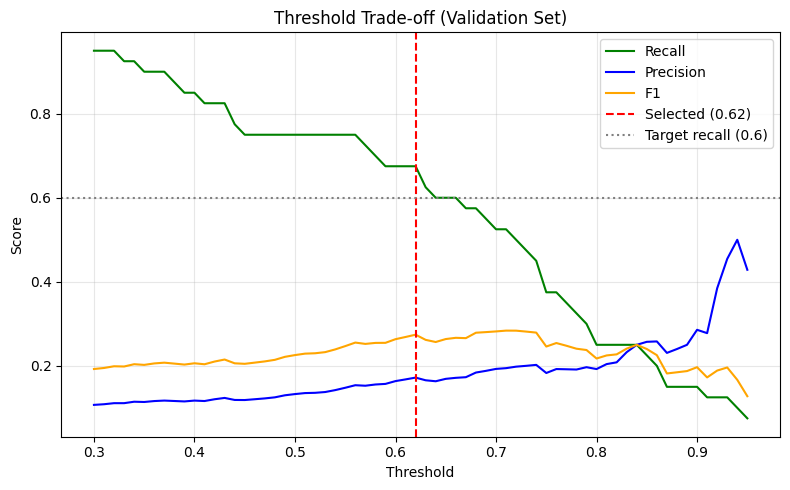

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, precision_score, f1_score
from sklearn.base import clone

print("=" * 60)
print("THRESHOLD SELECTION")
print("=" * 60)

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

best_pipeline_temp = clone(final_pipelines[best_model_name])
best_pipeline_temp.fit(X_train_sub, y_train_sub)

val_probabilities = best_pipeline_temp.predict_proba(X_val)[:, 1]

MIN_THRESHOLD   = 0.30
TARGET_RECALL   = 0.60

thresholds = np.arange(MIN_THRESHOLD, 0.96, 0.01)
threshold_results = []

for t in thresholds:
    val_pred = (val_probabilities >= t).astype(int)
    threshold_results.append({
        "threshold": t,
        "recall":    recall_score(y_val, val_pred, zero_division=0),
        "precision": precision_score(y_val, val_pred, zero_division=0),
        "f1":        f1_score(y_val, val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

valid = threshold_df[threshold_df["recall"] >= TARGET_RECALL]

if len(valid) > 0:

    best_threshold = valid.loc[valid["f1"].idxmax(), "threshold"]
    strategy = f"recall ≥ {TARGET_RECALL}, F1-max"
else:

    best_threshold = threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"]
    strategy = "F1-max (recall target unreachable)"

selected = threshold_df[threshold_df["threshold"] == best_threshold].iloc[0]

print(f"\nSelected model:      {best_model_name}")
print(f"Strategy:            {strategy}")
print(f"Selected threshold:  {best_threshold:.2f}")
print(f"Validation Recall:   {selected['recall']:.4f}")
print(f"Validation Precision:{selected['precision']:.4f}")
print(f"Validation F1:       {selected['f1']:.4f}")

test_probs = final_pipelines[best_model_name].predict_proba(X_test)[:, 1]
test_pred = (test_probs >= best_threshold).astype(int)

print(f"\nFINAL TEST SET (threshold = {best_threshold:.2f}):")
print(f"  Recall:    {recall_score(y_test, test_pred, zero_division=0):.4f}")
print(f"  Precision: {precision_score(y_test, test_pred, zero_division=0):.4f}")
print(f"  F1:        {f1_score(y_test, test_pred, zero_division=0):.4f}")
print(f"\nbest_threshold = {best_threshold:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["recall"],    label="Recall",    color="green")
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision", color="blue")
plt.plot(threshold_df["threshold"], threshold_df["f1"],        label="F1",        color="orange")
plt.axvline(x=best_threshold, color="red", linestyle="--",
            label=f"Selected ({best_threshold:.2f})")
plt.axhline(y=TARGET_RECALL, color="gray", linestyle=":",
            label=f"Target recall ({TARGET_RECALL})")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Trade-off (Validation Set)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("threshold_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

### **SHAP Explainability Analysis for the Selected Best Model**

In [37]:
import shap
import numpy as np
import pandas as pd

best_pipeline = final_pipelines[best_model_name]

best_estimator = best_pipeline.named_steps["model"]
best_preprocessor = best_pipeline.named_steps["preprocessor"]

X_test_processed = best_preprocessor.transform(X_test)

feature_names = best_preprocessor.get_feature_names_out()

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

if best_model_name in ["XGBoost", "Random Forest", "Decision Tree"]:
    shap_explainer = shap.TreeExplainer(best_estimator)
    shap_values = shap_explainer.shap_values(
        X_test_processed_df
    )

elif best_model_name == "Logistic Regression":
    background_data = shap.maskers.Independent(
        X_test_processed_df.sample(
            n=min(100, len(X_test_processed_df)),
            random_state=42
        )
    )

    shap_explainer = shap.Explainer(
        best_estimator.predict_proba,
        background_data
    )

    shap_values = shap_explainer(
        X_test_processed_df
    )

print("SHAP values calculated successfully.")
print("Selected model:", best_model_name)
print("Processed test-data shape:", X_test_processed_df.shape)


PermutationExplainer explainer: 1023it [00:27, 23.73it/s]                          

SHAP values calculated successfully.
Selected model: Logistic Regression
Processed test-data shape: (1022, 36)


SHAP-Based Feature Impact Analysis

In [38]:
import numpy as np
import pandas as pd
import plotly.express as px
import shap

if isinstance(shap_values, shap.Explanation):
    shap_array = np.asarray(shap_values.values)
else:
    shap_array = np.asarray(shap_values)

if shap_array.ndim == 3:
    if shap_array.shape[-1] == 2:
        shap_array = shap_array[:, :, 1]
    elif shap_array.shape[1] == 2:
        shap_array = shap_array[:, 1, :]

if shap_array.ndim != 2:
    raise ValueError(
        f"Expected 2D SHAP values, got shape {shap_array.shape}"
    )

shap_df = pd.DataFrame(
    shap_array,
    columns=feature_names
)

feature_order = (
    shap_df.abs()
    .mean(axis=0)
    .sort_values(ascending=False)
    .index
    .tolist()
)

plot_df = shap_df.melt(
    var_name="Feature",
    value_name="SHAP Value"
)

plot_df["Feature"] = pd.Categorical(
    plot_df["Feature"],
    categories=feature_order,
    ordered=True
)

np.random.seed(42)

plot_df["Feature_Position"] = (
    plot_df["Feature"].cat.codes
    + np.random.uniform(-0.25, 0.25, len(plot_df))
)

fig = px.scatter(
    plot_df,
    x="SHAP Value",
    y="Feature_Position",
    color="SHAP Value",
    hover_data={
        "Feature": True,
        "SHAP Value": ":.4f",
        "Feature_Position": False
    },
    color_continuous_scale=[
        [0.0, "#00B4D8"],
        [0.5, "#F8F9FA"],
        [1.0, "#7B2CBF"]
    ],
    labels={
        "SHAP Value": "SHAP Value",
        "Feature_Position": "Feature"
    },
    opacity=0.65
)

fig.update_yaxes(
    tickmode="array",
    tickvals=list(range(len(feature_order))),
    ticktext=feature_order,
    autorange="reversed"
)

fig.add_vline(
    x=0,
    line_width=2,
    line_dash="dash",
    line_color="gray"
)

fig.update_traces(
    marker=dict(size=7)
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        text="SHAP Summary Plot",
        x=0.5,
        font=dict(size=22, color="#2D3047")
    ),
    xaxis_title="SHAP Value",
    yaxis_title="Feature",
    height=700,
    width=1000,
    coloraxis_colorbar=dict(title="SHAP Value")
)

fig.show()

print("SHAP feature impact analysis completed.")
print("Number of features:", len(feature_order))
print("\nTop 10 features by mean absolute SHAP value:")

display(
    shap_df.abs()
    .mean(axis=0)
    .sort_values(ascending=False)
    .head(10)
    .rename("Mean Absolute SHAP Value")
    .to_frame()
)


SHAP feature impact analysis completed.
Number of features: 36

Top 10 features by mean absolute SHAP value:


,Mean Absolute SHAP Value
numeric__age,0.296748
numeric__age_bmi_interaction,0.084020
categorical__bmi_category_Obese,0.037596
categorical__age_group_40-60,0.034957
categorical__work_type_Private,0.034155
categorical__work_type_Self-employed,0.030745
numeric__bmi,0.029290
categorical__work_type_children,0.027819
numeric__age_glucose_interaction,0.023625
categorical__age_group_<40,0.021222


SHAP Feature Importance

In [39]:
if isinstance(shap_values, shap.Explanation):
    shap_array = np.asarray(shap_values.values)
else:
    shap_array = np.asarray(shap_values)

if shap_array.ndim == 3:
    if shap_array.shape[-1] == 2:
        shap_array = shap_array[:, :, 1]
    elif shap_array.shape[1] == 2:
        shap_array = shap_array[:, 1, :]

importance = np.abs(shap_array).mean(axis=0)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

fig = px.bar(
    importance_df,
    x="Importance",
    y="Feature",
    orientation="h",
    color="Importance",
    color_continuous_scale=[
        "#00B4D8",
        "#7B2CBF",
        "#E76F51"
    ],
    title="SHAP Feature Importance"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Mean |SHAP Value|",
    yaxis_title="Feature",
    yaxis=dict(autorange="reversed"),
    title_x=0.5
)

fig.show()

print("SHAP feature importance calculated successfully.")

display(importance_df.reset_index(drop=True))


SHAP feature importance calculated successfully.


,Feature,Importance
0,numeric__age,0.296748
1,numeric__age_bmi_interaction,0.084020
2,categorical__bmi_category_Obese,0.037596
3,categorical__age_group_40-60,0.034957
4,categorical__work_type_Private,0.034155
5,categorical__work_type_Self-employed,0.030745
6,numeric__bmi,0.029290
7,categorical__work_type_children,0.027819
8,numeric__age_glucose_interaction,0.023625
9,categorical__age_group_<40,0.021222


Individual Patient Prediction Using SHAP

In [40]:
patient_index = 0

if isinstance(shap_values, shap.Explanation):
    shap_array = np.asarray(shap_values.values)
else:
    shap_array = np.asarray(shap_values)

if shap_array.ndim == 3:
    if shap_array.shape[-1] == 2:

        values = shap_array[patient_index, :, 1]
    elif shap_array.shape[1] == 2:
        values = shap_array[patient_index, 1, :]
    else:
        raise ValueError(
            f"Unexpected SHAP array shape: {shap_array.shape}"
        )
elif shap_array.ndim == 2:
    values = shap_array[patient_index]
else:
    raise ValueError(
        f"Unexpected SHAP array shape: {shap_array.shape}"
    )

if len(values) != len(feature_names):
    raise ValueError(
        f"SHAP values ({len(values)}) do not match "
        f"feature names ({len(feature_names)})."
    )

idx = np.argsort(values)

fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=values[idx],
        y=np.array(feature_names)[idx],
        orientation="h",
        marker_color=[
            "#7B2CBF" if value > 0 else "#00B4D8"
            for value in values[idx]
        ],
        hovertemplate=(
            "<b>%{y}</b><br>"
            "SHAP value: %{x:.4f}"
            "<extra></extra>"
        )
    )
)

fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="gray"
)

fig.update_layout(
    title=f"Individual Patient SHAP Explanation - Patient {patient_index}",
    title_x=0.5,
    template="plotly_white",
    xaxis_title="SHAP Value",
    yaxis_title="Feature",
    height=600
)

fig.show()

print("Individual patient SHAP explanation generated successfully.")


Individual patient SHAP explanation generated successfully.


### **LIME explanations**

Selected model: Logistic Regression
Patient index: 0

LIME Explanation for Stroke:
numeric__age > 0.78 : 0.6065
numeric__age_bmi_interaction > 0.72 : -0.2088
categorical__work_type_children <= 0.00 : -0.1539
numeric__heart_disease <= -0.24 : -0.0824
categorical__work_type_Govt_job <= 0.00 : 0.0821
categorical__bmi_category_Underweight <= 0.00 : 0.0741
categorical__work_type_Self-employed <= 0.00 : 0.0685
0.00 < categorical__bmi_category_Obese <= 1.00 : 0.0674
numeric__bmi > 0.50 : 0.0616
categorical__work_type_Never_worked <= 0.00 : 0.0401


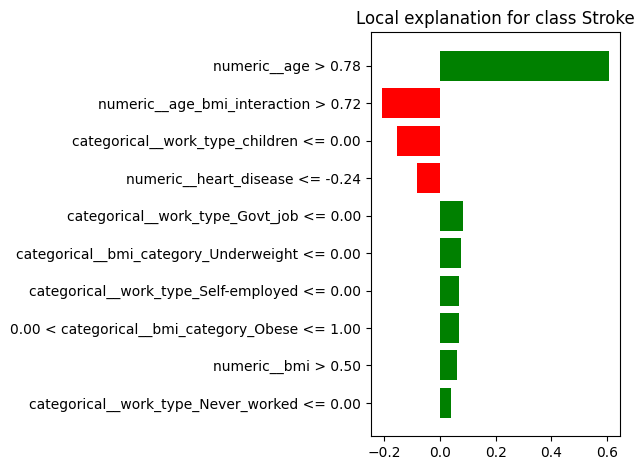

In [41]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import matplotlib.pyplot as plt

best_pipeline = final_pipelines[best_model_name]
best_preprocessor = best_pipeline.named_steps["preprocessor"]
best_estimator = best_pipeline.named_steps["model"]

X_train_processed = best_preprocessor.transform(X_train)
X_test_processed = best_preprocessor.transform(X_test)

X_train_processed = np.asarray(X_train_processed)
X_test_processed = np.asarray(X_test_processed)

feature_names = list(best_preprocessor.get_feature_names_out())

def lime_predict_proba(processed_data):
    return best_estimator.predict_proba(processed_data)

lime_explainer = LimeTabularExplainer(
    training_data=X_train_processed,
    feature_names=feature_names,
    class_names=["No Stroke", "Stroke"],
    mode="classification",
    random_state=42
)

patient_index = 0

lime_explanation = lime_explainer.explain_instance(
    data_row=X_test_processed[patient_index],
    predict_fn=lime_predict_proba,
    labels=(1,),
    num_features=10,
    num_samples=1000
)

print("Selected model:", best_model_name)
print("Patient index:", patient_index)
print("\nLIME Explanation for Stroke:")

for feature, weight in lime_explanation.as_list(label=1):
    print(feature, ":", round(weight, 4))

fig = lime_explanation.as_pyplot_figure(label=1)
fig.tight_layout()
plt.show()


LIME Local Explanation – Feature Contributions to Prediction

In [42]:
exp = lime_explanation.as_list(label=1)

features, values = zip(*exp)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=list(features),
    y=list(values),
    mode="markers+lines",
    marker=dict(
        size=12,
        color=[
            "#6A4C93" if v > 0 else "#1982C4"
            for v in values
        ]
    ),
    line=dict(color="#D9D9D9", width=2),
    hovertemplate=(
        "<b>%{x}</b><br>"
        "LIME Weight: %{y:.4f}"
        "<extra></extra>"
    )
))

fig.add_hline(
    y=0,
    line_dash="dash",
    line_color="#555555"
)

fig.update_layout(
    title="LIME Local Feature Contributions for Stroke Prediction",
    title_x=0.5,
    template="plotly_white",
    xaxis_title="Features",
    yaxis_title="LIME Weight",
    height=500,
    xaxis=dict(tickangle=-35),
    showlegend=False
)

fig.show()

print("LIME local feature contribution plot generated successfully.")


LIME local feature contribution plot generated successfully.


### **Cross-model feature consistency**

In [43]:
preprocessor = final_pipelines["Logistic Regression"].named_steps["preprocessor"]

feature_names = list(preprocessor.get_feature_names_out())

logistic_model = final_pipelines["Logistic Regression"].named_steps["model"]
decision_tree_model = final_pipelines["Decision Tree"].named_steps["model"]
random_forest_model = final_pipelines["Random Forest"].named_steps["model"]
xgb_model = final_pipelines["XGBoost"].named_steps["model"]

logistic_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": np.abs(logistic_model.coef_[0])
}).sort_values("Importance", ascending=False)

tree_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": decision_tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest_model.feature_importances_
}).sort_values("Importance", ascending=False)

xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Logistic Regression - Top 10 Features")
display(logistic_importance.head(10).reset_index(drop=True))

print("Decision Tree - Top 10 Features")
display(tree_importance.head(10).reset_index(drop=True))

print("Random Forest - Top 10 Features")
display(rf_importance.head(10).reset_index(drop=True))

print("XGBoost - Top 10 Features")
display(xgb_importance.head(10).reset_index(drop=True))

print("Cross-model feature importance analysis completed successfully.")


Logistic Regression - Top 10 Features


,Feature,Importance
0,numeric__age,3.396430
1,categorical__work_type_children,2.437834
2,categorical__bmi_category_Underweight,1.435453
3,numeric__age_bmi_interaction,1.328164
4,categorical__work_type_Self-employed,1.196549
5,categorical__work_type_Govt_job,0.933102
6,categorical__bmi_category_Obese,0.779271
7,categorical__age_group_40-60,0.757752
8,categorical__work_type_Private,0.748425
9,categorical__age_group_>80,0.577253


Decision Tree - Top 10 Features


,Feature,Importance
0,numeric__age,0.684085
1,categorical__age_group_60-80,0.109636
2,categorical__work_type_Private,0.075275
3,categorical__age_group_40-60,0.032247
4,categorical__smoking_status_never smoked,0.028229
5,categorical__bmi_category_Overweight,0.017177
6,numeric__heart_disease,0.016421
7,categorical__age_group_<40,0.013211
8,numeric__age_glucose_interaction,0.009121
9,categorical__work_type_Self-employed,0.007662


Random Forest - Top 10 Features


,Feature,Importance
0,numeric__age,0.196737
1,numeric__age_bmi_interaction,0.114760
2,categorical__age_group_60-80,0.099165
3,categorical__age_group_<40,0.091678
4,numeric__age_glucose_interaction,0.067322
5,categorical__ever_married_Yes,0.031278
6,categorical__work_type_Private,0.029857
7,categorical__age_group_40-60,0.029710
8,categorical__smoking_status_formerly smoked,0.026846
9,categorical__ever_married_No,0.024653


XGBoost - Top 10 Features


,Feature,Importance
0,numeric__age,0.169591
1,categorical__Residence_type_Rural,0.077402
2,categorical__age_group_60-80,0.062733
3,categorical__work_type_Private,0.057504
4,categorical__age_group_40-60,0.056779
5,categorical__smoking_status_formerly smoked,0.053695
6,categorical__bmi_category_Overweight,0.046553
7,categorical__smoking_status_Unknown,0.043099
8,categorical__gender_Female,0.039954
9,categorical__bmi_category_Obese,0.038071


Cross-model feature importance analysis completed successfully.


Top 10 Feature Importance Consistency Across Machine Learning Models

In [44]:
top_n = 10

consistency_table = pd.DataFrame({
    "Rank": range(1, top_n + 1),
    "Logistic Regression": logistic_importance.head(top_n)["Feature"].reset_index(drop=True),
    "Decision Tree": tree_importance.head(top_n)["Feature"].reset_index(drop=True),
    "Random Forest": rf_importance.head(top_n)["Feature"].reset_index(drop=True),
    "XGBoost": xgb_importance.head(top_n)["Feature"].reset_index(drop=True)
})

print("Top 10 Feature Importance Consistency Across Machine Learning Models")
display(consistency_table)

Top 10 Feature Importance Consistency Across Machine Learning Models


,Rank,Logistic Regression,Decision Tree,Random Forest,XGBoost
0,1,numeric__age,numeric__age,numeric__age,numeric__age
1,2,categorical__work_type_children,categorical__age_group_60-80,numeric__age_bmi_interaction,categorical__Residence_type_Rural
2,3,categorical__bmi_category_Underweight,categorical__work_type_Private,categorical__age_group_60-80,categorical__age_group_60-80
3,4,numeric__age_bmi_interaction,categorical__age_group_40-60,categorical__age_group_<40,categorical__work_type_Private
4,5,categorical__work_type_Self-employed,categorical__smoking_status_never smoked,numeric__age_glucose_interaction,categorical__age_group_40-60
5,6,categorical__work_type_Govt_job,categorical__bmi_category_Overweight,categorical__ever_married_Yes,categorical__smoking_status_formerly smoked
6,7,categorical__bmi_category_Obese,numeric__heart_disease,categorical__work_type_Private,categorical__bmi_category_Overweight
7,8,categorical__age_group_40-60,categorical__age_group_<40,categorical__age_group_40-60,categorical__smoking_status_Unknown
8,9,categorical__work_type_Private,numeric__age_glucose_interaction,categorical__smoking_status_formerly smoked,categorical__gender_Female
9,10,categorical__age_group_>80,categorical__work_type_Self-employed,categorical__ever_married_No,categorical__bmi_category_Obese


Frequency of Features Appearing in Top 10 Across Models

In [45]:
all_top_features = pd.concat([
    logistic_importance.head(top_n)[["Feature"]],
    tree_importance.head(top_n)[["Feature"]],
    rf_importance.head(top_n)[["Feature"]],
    xgb_importance.head(top_n)[["Feature"]]
], ignore_index=True)

feature_consistency = (
    all_top_features["Feature"]
    .value_counts()
    .rename_axis("Feature")
    .reset_index(name="Number_of_Models_in_Top_10")
)

display(feature_consistency)

print("Feature frequency analysis completed successfully.")


,Feature,Number_of_Models_in_Top_10
0,numeric__age,4
1,categorical__age_group_40-60,4
2,categorical__work_type_Private,4
3,categorical__age_group_60-80,3
4,categorical__work_type_Self-employed,2
5,numeric__age_bmi_interaction,2
6,categorical__bmi_category_Overweight,2
7,categorical__smoking_status_formerly smoked,2
8,numeric__age_glucose_interaction,2
9,categorical__bmi_category_Obese,2


Feature frequency analysis completed successfully.


SHAP-Based Top 10 Feature Importance

In [46]:
if isinstance(shap_values, shap.Explanation):
    shap_array = np.asarray(shap_values.values)
else:
    shap_array = np.asarray(shap_values)

if shap_array.ndim == 3:
    if shap_array.shape[-1] == 2:

        shap_array = shap_array[:, :, 1]
    elif shap_array.shape[1] == 2:

        shap_array = shap_array[:, 1, :]
    else:
        raise ValueError(
            f"Unexpected SHAP output shape: {shap_array.shape}"
        )

if shap_array.ndim != 2:
    raise ValueError(
        f"Expected a 2D SHAP array, got shape {shap_array.shape}"
    )

if shap_array.shape[1] != len(feature_names):
    raise ValueError(
        f"SHAP features ({shap_array.shape[1]}) do not match "
        f"feature names ({len(feature_names)})."
    )

mean_abs_shap = np.abs(shap_array).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": list(feature_names),
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("SHAP-Based Top 10 Feature Importance")
display(shap_importance.head(10))

print("SHAP feature importance analysis completed successfully.")


SHAP-Based Top 10 Feature Importance


,Feature,Mean_Absolute_SHAP
0,numeric__age,0.296748
1,numeric__age_bmi_interaction,0.084020
2,categorical__bmi_category_Obese,0.037596
3,categorical__age_group_40-60,0.034957
4,categorical__work_type_Private,0.034155
5,categorical__work_type_Self-employed,0.030745
6,numeric__bmi,0.029290
7,categorical__work_type_children,0.027819
8,numeric__age_glucose_interaction,0.023625
9,categorical__age_group_<40,0.021222


SHAP feature importance analysis completed successfully.


### **Gradio-Based Stroke Risk Prediction Clinical Decision Support System (CDSS)**

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
import traceback


required_objects = [
    "X",
    "create_engineered_features",
    "best_pipeline",
    "best_preprocessor",
    "feature_names",
    "shap_explainer",
    "best_threshold",
    "best_model_name",
    "strategy",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Please run the model-training and SHAP setup cells first. "
        f"Missing objects: {missing_objects}"
    )

print("=" * 60)
print("SELECTED MODEL")
print("=" * 60)
print("Model:", best_model_name)
print("Model-training subset:", X.shape)
print("Validation-selected threshold:", round(float(best_threshold), 2))
print("Decision strategy:", strategy)
print("SHAP explainer prepared successfully.")



def predict_stroke(
    gender,
    age,
    hypertension,
    heart_disease,
    ever_married,
    work_type,
    residence_type,
    avg_glucose_level,
    bmi,
    smoking_status,
):
    fig = None

    try:

        values = [
            gender, age, hypertension, heart_disease,
            ever_married, work_type, residence_type,
            avg_glucose_level, bmi, smoking_status,
        ]

        if any(v is None for v in values):
            raise gr.Error(
                "Please complete all patient information."
            )


        try:
            age = float(age)
            avg_glucose_level = float(avg_glucose_level)
            bmi = float(bmi)
            hypertension = int(hypertension)
            heart_disease = int(heart_disease)
        except (ValueError, TypeError):
            raise gr.Error(
                "Please enter valid patient information."
            )

        if not np.isfinite(age) or not 0 <= age <= 120:
            raise gr.Error("Age must be between 0 and 120.")

        if (
            not np.isfinite(avg_glucose_level)
            or avg_glucose_level <= 0
        ):
            raise gr.Error(
                "Average glucose level must be greater than zero."
            )

        if not np.isfinite(bmi) or bmi <= 0:
            raise gr.Error("BMI must be greater than zero.")

        if hypertension not in (0, 1):
            raise gr.Error("Hypertension must be 0 or 1.")

        if heart_disease not in (0, 1):
            raise gr.Error("Heart disease must be 0 or 1.")



        patient = pd.DataFrame([{
            "gender": gender,
            "age": age,
            "hypertension": hypertension,
            "heart_disease": heart_disease,
            "ever_married": ever_married,
            "work_type": work_type,
            "Residence_type": residence_type,
            "avg_glucose_level": avg_glucose_level,
            "bmi": bmi,
            "smoking_status": smoking_status,
        }])


        patient = create_engineered_features(patient)

        if not isinstance(patient, pd.DataFrame):
            raise gr.Error(
                "create_engineered_features() must return "
                "a pandas DataFrame."
            )


        expected_columns = list(X.columns)

        missing_columns = [
            col for col in expected_columns
            if col not in patient.columns
        ]

        if missing_columns:
            raise gr.Error(
                f"Missing engineered features: {missing_columns}. "
                "Check your feature-engineering function."
            )

        patient = patient[expected_columns]



        probabilities = best_pipeline.predict_proba(patient)
        model_classes = list(best_pipeline.classes_)

        if 1 not in model_classes:
            raise gr.Error(
                "The model does not contain stroke class 1."
            )

        stroke_class_index = model_classes.index(1)
        probability = float(
            probabilities[0, stroke_class_index]
        )

        prediction = int(probability >= float(best_threshold))


        patient_processed = best_preprocessor.transform(patient)

        if hasattr(patient_processed, "toarray"):
            patient_processed = patient_processed.toarray()

        patient_processed = np.asarray(patient_processed)

        if patient_processed.ndim == 1:
            patient_processed = patient_processed.reshape(1, -1)

        if patient_processed.ndim != 2:
            raise gr.Error(
                f"Unexpected processed-data shape: "
                f"{patient_processed.shape}"
            )

        if patient_processed.shape[1] != len(feature_names):
            raise gr.Error(
                "Processed feature count does not match feature_names. "
                f"Processed: {patient_processed.shape[1]}, "
                f"names: {len(feature_names)}."
            )

        patient_processed_df = pd.DataFrame(
            patient_processed,
            columns=feature_names,
        )



        shap_explanation = shap_explainer(patient_processed_df)

        if isinstance(shap_explanation, (list, tuple)):
            shap_values_raw = shap_explanation[
                min(stroke_class_index, len(shap_explanation) - 1)
            ]

            if hasattr(shap_values_raw, "values"):
                shap_values_raw = shap_values_raw.values
        else:
            shap_values_raw = shap_explanation.values

        shap_values_raw = np.asarray(shap_values_raw)
        n_features = len(feature_names)


        if shap_values_raw.ndim == 1:
            shap_values_patient = shap_values_raw

        elif shap_values_raw.ndim == 2:
            if (
                shap_values_raw.shape[0] == 1
                and shap_values_raw.shape[1] == n_features
            ):
                shap_values_patient = shap_values_raw[0]

            elif (
                shap_values_raw.shape[0] == n_features
                and shap_values_raw.shape[1] == 1
            ):
                shap_values_patient = shap_values_raw[:, 0]

            else:
                raise gr.Error(
                    f"Unexpected 2D SHAP shape: "
                    f"{shap_values_raw.shape}"
                )

        elif shap_values_raw.ndim == 3:

            if (
                shap_values_raw.shape[0] == 1
                and shap_values_raw.shape[1] == n_features
            ):
                shap_values_patient = shap_values_raw[
                    0, :, stroke_class_index
                ]


            elif (
                shap_values_raw.shape[0] == 1
                and shap_values_raw.shape[2] == n_features
            ):
                shap_values_patient = shap_values_raw[
                    0, stroke_class_index, :
                ]

            elif (
                shap_values_raw.shape[1] == 1
                and shap_values_raw.shape[2] == n_features
            ):
                shap_values_patient = shap_values_raw[
                    stroke_class_index, 0, :
                ]

            else:
                raise gr.Error(
                    f"Unsupported 3D SHAP shape: "
                    f"{shap_values_raw.shape}"
                )

        else:
            raise gr.Error(
                f"Unsupported SHAP dimensions: "
                f"{shap_values_raw.shape}"
            )

        shap_values_patient = np.asarray(
            shap_values_patient
        ).reshape(-1)

        if len(shap_values_patient) != n_features:
            raise gr.Error(
                "SHAP values do not match the processed features."
            )

        if not np.isfinite(shap_values_patient).all():
            raise gr.Error(
                "SHAP returned non-finite values."
            )


        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "SHAP_Value": shap_values_patient,
        })

        importance_df["Absolute_SHAP"] = (
            importance_df["SHAP_Value"].abs()
        )

        plot_df = (
            importance_df
            .nlargest(
                min(10, len(importance_df)),
                "Absolute_SHAP",
            )
            .sort_values("SHAP_Value")
        )


        fig, ax = plt.subplots(figsize=(10, 6))

        bar_colors = [
            "#E76F51" if value > 0 else "#457B9D"
            for value in plot_df["SHAP_Value"]
        ]

        ax.barh(
            plot_df["Feature"].astype(str),
            plot_df["SHAP_Value"],
            color=bar_colors,
            edgecolor="black",
        )

        ax.axvline(x=0, color="black", linewidth=1)

        ax.set_xlabel(
            "SHAP value (contribution to model output)"
        )
        ax.set_ylabel("Processed feature")
        ax.set_title("Top SHAP Contributions to Stroke Prediction")
        fig.tight_layout()

        # ----------------------------------------------------
        # Build prediction result
        # ----------------------------------------------------

        if prediction == 1:
            prediction_label = "STROKE CLASS PREDICTED"

            interpretation = (
                "The model-predicted probability is at or above "
                "the validation-selected decision threshold."
            )

            recommendation = """
### Suggested follow-up

Discuss this result and relevant risk factors with a qualified
healthcare professional. This model prediction is not a diagnosis
and must not be used alone to make medical decisions.
"""

        else:
            prediction_label = "NO STROKE CLASS PREDICTED"

            interpretation = (
                "The model-predicted probability is below "
                "the validation-selected decision threshold."
            )

            recommendation = """
### Important follow-up information

A result below the model threshold does not mean stroke is
impossible. Seek professional assessment when appropriate.
"""

        result = f"""
## Stroke Prediction Result

**Selected model:** {best_model_name}

**Predicted class:** {prediction_label}

**Model-predicted probability of stroke:** {probability * 100:.2f}%

**Validation-selected threshold:** {float(best_threshold):.2f}

**Decision rule:** {strategy}

**Interpretation:** {interpretation}

**Note:** This is a machine-learning prediction, not a clinical diagnosis.
"""

        return result, fig, recommendation

    except gr.Error:
        if fig is not None:
            plt.close(fig)
        raise

    except Exception as e:
        traceback.print_exc()

        if fig is not None:
            plt.close(fig)

        raise gr.Error(
            f"Prediction failed: {type(e).__name__}: {e}. "
            "Check the Colab output for the full traceback."
        )



with gr.Blocks(
    title="Stroke Prediction CDSS",
    theme=gr.themes.Soft(),
) as demo:

    gr.Markdown(f"""
# Stroke Prediction CDSS

### Explainable Machine Learning Research Prototype

Enter patient information to obtain a model prediction
and a SHAP-based explanation.

**Selected model:** {best_model_name}

**Explainability:** SHAP

**Validation-selected threshold:** {float(best_threshold):.2f}

**Decision rule:** {strategy}

**Model-selection criterion:** Highest mean cross-validation ROC-AUC.
""")

    with gr.Row():

        with gr.Column():
            gr.Markdown("## Patient Information")

            gender = gr.Radio(
                choices=["Female", "Male", "Other"],
                label="Gender",
                value="Female",
            )

            age = gr.Slider(
                minimum=0,
                maximum=120,
                value=65,
                step=1,
                label="Age (years)",
            )

            hypertension = gr.Radio(
                choices=[0, 1],
                label="Hypertension",
                value=0,
                info="0 = No, 1 = Yes",
            )

            heart_disease = gr.Radio(
                choices=[0, 1],
                label="Heart Disease",
                value=0,
                info="0 = No, 1 = Yes",
            )

            ever_married = gr.Radio(
                choices=["No", "Yes"],
                label="Ever Married",
                value="Yes",
            )

            work_type = gr.Dropdown(
                choices=[
                    "Private",
                    "Self-employed",
                    "Govt_job",
                    "children",
                    "Never_worked",
                ],
                label="Work Type",
                value="Private",
            )

            residence_type = gr.Radio(
                choices=["Rural", "Urban"],
                label="Residence Type",
                value="Urban",
            )

            avg_glucose_level = gr.Number(
                label="Average Glucose Level",
                value=100.0,
            )

            bmi = gr.Number(
                label="BMI",
                value=25.0,
            )

            smoking_status = gr.Dropdown(
                choices=[
                    "never smoked",
                    "formerly smoked",
                    "smokes",
                    "Unknown",
                ],
                label="Smoking Status",
                value="never smoked",
            )

            predict_btn = gr.Button(
                "Predict Stroke Class",
                variant="primary",
                size="lg",
            )

            clear_btn = gr.ClearButton(
                components=[
                    gender,
                    age,
                    hypertension,
                    heart_disease,
                    ever_married,
                    work_type,
                    residence_type,
                    avg_glucose_level,
                    bmi,
                    smoking_status,
                ],
                value="Clear Patient Inputs",
            )

        with gr.Column():
            gr.Markdown("## Prediction and Explanation")

            output_text = gr.Markdown(
                "Enter patient information and click Predict."
            )

            output_plot = gr.Plot(
                label="SHAP Feature Contributions"
            )

            output_recommendation = gr.Markdown(
                "Follow-up information will appear here."
            )

    predict_btn.click(
        fn=predict_stroke,
        inputs=[
            gender,
            age,
            hypertension,
            heart_disease,
            ever_married,
            work_type,
            residence_type,
            avg_glucose_level,
            bmi,
            smoking_status,
        ],
        outputs=[
            output_text,
            output_plot,
            output_recommendation,
        ],
    )

    gr.Markdown("""
---

**Research disclaimer:** This prototype is for educational and
research purposes only. It is not a clinically validated medical
device and must not replace professional medical assessment.

If stroke symptoms occur, seek emergency medical care immediately.
""")


print("\n" + "=" * 60)
print("STARTING THE STROKE PREDICTION CDSS")
print("=" * 60)
print("Selected model:", best_model_name)
print(
    "Validation-selected threshold:",
    round(float(best_threshold), 2),
)
print("Decision rule:", strategy)
print("=" * 60)

try:
    demo.close()
except Exception:
    pass

demo.launch(debug=False, share=True)


SELECTED MODEL
Model: Logistic Regression
Model-training subset: (5110, 16)
Validation-selected threshold: 0.62
Decision strategy: recall ≥ 0.6, F1-max
SHAP explainer prepared successfully.

STARTING THE STROKE PREDICTION CDSS
Selected model: Logistic Regression
Validation-selected threshold: 0.62
Decision rule: recall ≥ 0.6, F1-max
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b0205c68c10c8e88c9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [48]:
import joblib
from pathlib import Path

best_model_name = (
    cv_results_df
    .sort_values("ROC-AUC", ascending=False)
    .iloc[0]["Model"]
)

best_pipeline = final_pipelines[best_model_name]
best_preprocessor = best_pipeline.named_steps["preprocessor"]
best_estimator = best_pipeline.named_steps["model"]

if "best_threshold" not in globals():
    raise RuntimeError(
        "best_threshold is missing. Run the threshold-selection cell first."
    )

output_dir = Path("stroke_model_artifacts")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(best_pipeline,                     output_dir / "best_pipeline.joblib")
joblib.dump(final_pipelines["Logistic Regression"], output_dir / "logistic_regression_pipeline.joblib")
joblib.dump(final_pipelines["Decision Tree"],       output_dir / "decision_tree_pipeline.joblib")
joblib.dump(final_pipelines["Random Forest"],       output_dir / "random_forest_pipeline.joblib")
joblib.dump(final_pipelines["XGBoost"],             output_dir / "xgboost_pipeline.joblib")

joblib.dump(best_preprocessor, output_dir / "best_preprocessor.joblib")
joblib.dump(best_threshold,    output_dir / "best_threshold.joblib")
joblib.dump(best_model_name,   output_dir / "best_model_name.joblib")

results_df.to_csv(output_dir / "model_results.csv", index=False)
cv_results_df.to_csv(output_dir / "five_fold_cv_results.csv", index=False)
feature_consistency.to_csv(output_dir / "feature_consistency.csv", index=False)
shap_importance.to_csv(output_dir / "shap_feature_importance.csv", index=False)
df.to_csv(output_dir / "cleaned_stroke_dataset.csv", index=False)

print(f"   Saved all models + threshold + results")
print(f"   Best model: {best_model_name}")
print(f"   Threshold:  {best_threshold:.2f}")
print(f"   Location:   {output_dir}/")

   Saved all models + threshold + results
   Best model: Logistic Regression
   Threshold:  0.62
   Location:   stroke_model_artifacts/


In [49]:
reloaded_pipeline   = joblib.load(output_dir / "best_pipeline.joblib")
reloaded_threshold  = joblib.load(output_dir / "best_threshold.joblib")
reloaded_model_name = joblib.load(output_dir / "best_model_name.joblib")

reloaded_preproc = reloaded_pipeline.named_steps["preprocessor"]
reloaded_model   = reloaded_pipeline.named_steps["model"]

print(f"Reloaded threshold:  {reloaded_threshold}")
print(f"Reloaded model:      {type(reloaded_model).__name__}")
print(f"Reloaded preproc:    {type(reloaded_preproc).__name__}")
print(f"Reloaded model name: {reloaded_model_name}")

_test_probs = reloaded_pipeline.predict_proba(X_test)[:, 1]
print(f"\nReload sanity check (first 3 probabilities): {_test_probs[:3]}")

Reloaded threshold:  0.6200000000000003
Reloaded model:      LogisticRegression
Reloaded preproc:    ColumnTransformer
Reloaded model name: Logistic Regression

Reload sanity check (first 3 probabilities): [0.36821865 0.25792283 0.02251383]
